# Learning module 13 — Find one Search control, tap once, and observe the result

**Small milestone:** use a fresh native observation, confirm that the Search tab locator matches exactly one suitable control, tap it once, then verify the Search screen is visible. Save before/after evidence and close the session. No query is entered and no Interstellar assertion is evaluated.

We are still making these decisions ourselves, without an LLM or agent. The locator comes from observed native attributes, not from guessing an identifier from the English scenario. For this example, the app source also defines the expected destination:

| Purpose | Identifier | Evidence source |
| --- | --- | --- |
| Control to tap | `movies.shell.tab.search` | Captured native hierarchy; `client/apps/app/lib/core/router/app_router.dart`. |
| Destination to verify | `movies.search.screen` | `client/packages/search_feature/lib/presentation/views/search_view.dart`. |

App knowledge supplies the intended destination; fresh runtime observations determine whether those elements are actually present now. Later, approved app profiles/RAG can supply such knowledge to the agent. We are not building that layer in this exercise.

The important action code is:

```python
matches = session_driver.find_elements(AppiumBy.ACCESSIBILITY_ID, "movies.shell.tab.search")
if len(matches) != 1:
    raise RuntimeError("Expected exactly one Search control.")
target = matches[0]
# Check the actual native type/name and visible/enabled state before proceeding.
target.click()  # Exactly one click call; no automatic retry.
```

`find_elements` gives us a list, so zero or multiple matches are explicit blockers instead of silently choosing the first. In XCUITest, the accessibility-ID locator is an alias of the native name strategy; a name can still fall back to a label. For our app we have both observed the identifier and checked its declaration in Flutter. A Flutter `ValueKey` alone is not the native accessibility identifier. [XCUITest locator strategies](https://appium.github.io/appium-xcuitest-driver/latest/reference/locator-strategies/)

After the tap, a read-only wait checks for exactly one **displayed** Search-screen marker. Repeated observation is different from repeatedly tapping. If the tap request errors or times out, we record that it was attempted and do not retry: execution may have occurred despite a failed response.

**Prerequisites:** run this notebook's setup cells. The code revalidates the selected target and opens its own session as before. Current state is preserved; it may differ from any old screenshot. Run serially on this Simulator. The earlier dependency findings remain unresolved.

The lifecycle below repeats module 12. A small `capture_phase()` helper saves the same XML/PNG evidence before and after the action. Capture status, click acknowledgment, destination verification, and cleanup are separate facts. An already-visible Search screen permits checking the action, but does not establish a transition from another screen.


## This notebook

Part **13 — Locate Search and tap once** of the learning sequence. [Notebook index](README.md).

Select the project's `.venv` Python kernel and run this notebook from top to bottom. Its Python setup is included locally; running another notebook in another kernel does not populate this one's variables or PATH. The supported working directories are the project root, `server/`, and `server/sample_scenarios/`.

**Execution scope:** One Search-tab tap; preserves the tab navigation stack.

Saved lesson outputs and embedded screenshots are historical snapshots preserved during the split on November 3, 2026. Newly included setup cells have no saved outputs. Rerunning an executable scenario creates fresh local artifacts; these continue living in `server/.tools/`, not beside the notebooks.

### Setup for this notebook

These source-only prerequisite cells are repeated intentionally so the lesson is runnable in a fresh kernel. They configure local values/environment and inspect tool versions; they do not launch an Appium server, create a session, or tap/type in the app. The original lessons remain linked for explanation.


In [1]:
# Setup: Sample scenario input (lesson 01)
from pprint import pprint

scenario_text = (
    "In Movies, search for Interstellar, open the 2014 movie, "
    "and verify that its details show the title Interstellar "
    "and release year 2014."
)

scenario_input = {
    "instruction": scenario_text,
    "application_name": "Movies",
    "application_profile_ref": None,
    "requested_actions": [
        "search_for_movie",
        "open_matching_movie_details",
    ],
    "search_query": "Interstellar",
    "target_item_identity": {"title": "Interstellar", "release_year": 2014},
    "expected_title": "Interstellar",
    "expected_release_year": 2014,
    "title_matching_rule": "exact",  # Proposed comparison rule for this exercise.
}

pprint(scenario_input, sort_dicts=False)


{'instruction': 'In Movies, search for Interstellar, open the 2014 movie, and '
                'verify that its details show the title Interstellar and '
                'release year 2014.',
 'application_name': 'Movies',
 'application_profile_ref': None,
 'requested_actions': ['search_for_movie', 'open_matching_movie_details'],
 'search_query': 'Interstellar',
 'target_item_identity': {'title': 'Interstellar', 'release_year': 2014},
 'expected_title': 'Interstellar',
 'expected_release_year': 2014,
 'title_matching_rule': 'exact'}


In [2]:
# Setup: Recorded run profile (lesson 03)
from pprint import pprint

run_profile = {
    "id": "movies-ios-local",
    "platform": "ios",
    "execution_provider": "local",
    "app_bundle_id": "com.example.movies",
    "simulator_udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
}

app_profiles = {run_profile["id"]: run_profile}
scenario_input["application_profile_ref"] = run_profile["id"]
selected_profile = app_profiles[scenario_input["application_profile_ref"]]

print("Scenario profile reference:", scenario_input["application_profile_ref"])
pprint(selected_profile, sort_dicts=False)


Scenario profile reference: movies-ios-local
{'id': 'movies-ios-local',
 'platform': 'ios',
 'execution_provider': 'local',
 'app_bundle_id': 'com.example.movies',
 'simulator_udid': '4F0707AE-45BC-464D-9099-6EE76C3740A9'}


In [3]:
# Setup: Local Node activation (lesson 05)
import os
from pathlib import Path
import shutil
import subprocess

notebook_cwd = Path.cwd().resolve()
server_candidates = (notebook_cwd, notebook_cwd / "server", *notebook_cwd.parents)
server_dir = next((candidate for candidate in server_candidates
                   if (candidate / ".node-version").is_file()
                   and (candidate / "package.json").is_file()
                   and (candidate / "sample_scenarios").is_dir()), None)
if server_dir is None:
    raise RuntimeError("Run from the project root, server, or sample_scenarios folder.")

node_version = (server_dir / ".node-version").read_text().strip()
node_bin = server_dir / ".tools" / f"node-v{node_version}-darwin-arm64" / "bin"
if not (node_bin / "node").is_file():
    raise FileNotFoundError(f"Project-local Node is missing: {node_bin}")

path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(node_bin)]
os.environ["PATH"] = os.pathsep.join([str(node_bin), *path_entries])

print("Selected Node:", shutil.which("node"))
print("Node version:", subprocess.check_output(["node", "--version"], text=True, timeout=10).strip())
print("npm version:", subprocess.check_output(["npm", "--version"], text=True, timeout=10).strip())


Selected Node: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/node-v24.22.2-darwin-arm64/bin/node
Node version: v24.22.2
npm version: 11.19.1


In [4]:
# Setup: Local Appium activation (lesson 06)
import json
import os
import shutil
import subprocess

if "server_dir" not in globals() or "node_bin" not in globals():
    raise RuntimeError("Run the Node setup cell in this notebook first.")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime first.")

appium_bin_dir = server_dir / "node_modules" / ".bin"
appium_executable = appium_bin_dir / "appium"
if not appium_executable.is_file():
    raise FileNotFoundError("The project-local Appium package is missing.")

os.environ["APPIUM_HOME"] = str(server_dir / ".tools" / "appium")
os.environ["npm_config_cache"] = str(server_dir / ".tools" / "npm-cache")
path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(appium_bin_dir)]
os.environ["PATH"] = os.pathsep.join([str(appium_bin_dir), *path_entries])

expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
actual_version = subprocess.check_output(
    [str(appium_executable), "--version"], cwd=server_dir, text=True, timeout=30
).strip()
if actual_version != expected_version:
    raise RuntimeError(f"Expected Appium {expected_version}, found {actual_version}.")

print("Selected Appium:", shutil.which("appium"))
print("Appium version:", actual_version)
print("Appium home:", os.environ["APPIUM_HOME"])


Selected Appium: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/node_modules/.bin/appium
Appium version: 3.9.0
Appium home: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium


dbug Appium Creating hash file directory: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium/node_modules/.cache/appium


In [5]:
# Setup: Local iOS options (lesson 09)
import json
from appium.options.ios import XCUITestOptions

if "selected_profile" not in globals():
    raise RuntimeError("Run the scenario/profile setup cells in this notebook first.")
if selected_profile.get("platform") != "ios":
    raise ValueError("This example requires an iOS run profile.")
for field in ["app_bundle_id", "simulator_udid"]:
    value = selected_profile.get(field)
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"The selected profile needs a nonempty {field}.")

ios_options = XCUITestOptions()
ios_options.udid = selected_profile["simulator_udid"]
ios_options.bundle_id = selected_profile["app_bundle_id"]
ios_options.no_reset = True
ios_options.full_reset = False

session_request = ios_options.to_w3c()
print(json.dumps(session_request, indent=2))


{
  "capabilities": {
    "firstMatch": [
      {}
    ],
    "alwaysMatch": {
      "appium:automationName": "XCUITest",
      "platformName": "iOS",
      "appium:udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
      "appium:bundleId": "com.example.movies",
      "appium:noReset": true,
      "appium:fullReset": false
    }
  }
}


In [7]:
import json
import sys
import os
import shutil
import socket
import subprocess
import tempfile
import time
import urllib.error
import urllib.request
from appium import webdriver
from appium.options.ios import XCUITestOptions
from appium.webdriver.client_config import AppiumClientConfig
from selenium.webdriver.common.proxy import Proxy
from appium.webdriver.common.appiumby import AppiumBy
from selenium.webdriver.support.ui import WebDriverWait
from pathlib import Path
from datetime import datetime, timezone
import xml.etree.ElementTree as ET

navigation_result = None

if not all(name in globals() for name in ("server_dir", "node_bin", "appium_executable", "ios_options")):
    raise RuntimeError("Run this notebook's setup cells first (and its definitions cell where present).")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime.")
if os.environ.get("APPIUM_HOME") != str(server_dir / ".tools" / "appium"):
    raise RuntimeError("Reactivate the project-local Appium home.")
if ios_options.no_reset is not True or ios_options.full_reset is not False:
    raise ValueError("Rerun this notebook's profile/options setup cells to restore this exercise's explicit reset policy.")

# Revalidate the profile/options and installed target immediately before this run.
if "selected_profile" not in globals():
    raise RuntimeError("Run this notebook's profile setup cell first.")
if selected_profile.get("platform") != "ios" or selected_profile.get("execution_provider") != "local":
    raise ValueError("This example requires the local iOS profile.")
if ios_options.udid != selected_profile["simulator_udid"] or ios_options.bundle_id != selected_profile["app_bundle_id"]:
    raise ValueError("The profile/options differ; rerun this notebook's profile/options setup cells.")
devices = json.loads(subprocess.check_output(
    ["xcrun", "simctl", "list", "devices", "--json"], text=True, timeout=20,
))
targets = [d for entries in devices["devices"].values() for d in entries
           if d["udid"] == ios_options.udid]
if len(targets) != 1 or targets[0]["state"] != "Booted" or not targets[0].get("isAvailable"):
    raise RuntimeError("The selected Simulator must be available and booted.")
app_path = subprocess.check_output(
    ["xcrun", "simctl", "get_app_container", ios_options.udid, ios_options.bundle_id, "app"],
    text=True, timeout=20,
).strip()
if not Path(app_path).is_dir():
    raise RuntimeError("The installed Movies container could not be verified.")

host, port, wda_port = "127.0.0.1", 4723, 8100
with socket.socket() as probe:
    probe.bind((host, port))  # Leave an existing Appium server alone.

connection_options = XCUITestOptions().load_capabilities(ios_options.to_capabilities())
connection_options.set_capability("appium:wdaBindingIP", host)
connection_options.set_capability("appium:wdaLocalPort", wda_port)
server_url = f"http://{host}:{port}"
client_config = AppiumClientConfig(
    remote_server_addr=server_url, timeout=300,
    proxy=Proxy({"proxyType": "direct"}),
    init_args_for_pool_manager={"init_args_for_pool_manager": {"retries": 0}},
)
expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
log_dir = server_dir / ".tools" / "logs"
log_dir.mkdir(parents=True, exist_ok=True)
with tempfile.NamedTemporaryFile(mode="w", prefix="search-tap-config-", suffix=".json",
                                 dir=log_dir, delete=False) as config_file:
    json.dump({"server": {}}, config_file)
status_opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))
session_driver, session_process, session_result = None, None, None
with tempfile.NamedTemporaryFile(mode="w", prefix="search-tap-check-", suffix=".log",
                                 dir=log_dir, delete=False) as session_log:
    print("Server/session log:", session_log.name, flush=True)
    try:
        session_process = subprocess.Popen(
            [str(node_bin / "node"), str(appium_executable), "--config", config_file.name,
             "--address", host, "--port", str(port), "--log-no-colors", "--log-timestamp"],
            cwd=server_dir, env=os.environ.copy(), stdout=session_log, stderr=subprocess.STDOUT,
        )
        print("Owned Appium PID:", session_process.pid, flush=True)
        deadline = time.monotonic() + 30
        while time.monotonic() < deadline:
            if session_process.poll() is not None:
                raise RuntimeError(f"Appium exited early; inspect {session_log.name}")
            try:
                with status_opener.open(server_url + "/status", timeout=2) as response:
                    server_status = json.load(response)["value"]
                break
            except urllib.error.URLError:
                time.sleep(0.25)
        else:
            raise TimeoutError(f"Appium startup timed out; inspect {session_log.name}")
        if server_status.get("ready") is not True or server_status.get("build", {}).get("version") != expected_version:
            raise RuntimeError("Appium did not return the expected readiness/version.")
        if session_process.poll() is not None:
            raise RuntimeError("The owned server stopped before session creation.")
        print("Requesting XCUITest session; first WDA setup may take time...", flush=True)
        session_driver = webdriver.Remote(
            command_executor=server_url, options=connection_options, client_config=client_config,
        )
        if not session_driver.session_id:
            raise RuntimeError("The client did not receive a session ID.")
        session_result = {"session_id": session_driver.session_id,
                          "returned_capabilities": session_driver.capabilities}
        client_config.timeout = 20  # Bound each action/observation request after startup.
        observation_root = server_dir / ".tools" / "observations"
        observation_root.mkdir(parents=True, exist_ok=True)
        evidence_dir = Path(tempfile.mkdtemp(prefix="search-tap-", dir=observation_root))
        manifest_path = evidence_dir / "manifest.json"
        locator = "movies.shell.tab.search"
        destination = "movies.search.screen"
        navigation_result = {
            "session_id": session_driver.session_id,
            "returned_target": {key: session_driver.capabilities.get(key)
                                for key in ("platformName", "platformVersion", "udid", "bundleId")},
            "server_log": session_log.name,
            "action": {"strategy": AppiumBy.ACCESSIBILITY_ID, "locator": locator,
                       "attempted": False, "acknowledged": False},
            "destination": destination, "verification_status": "not_checked", "evidence": {},
        }

        def save_manifest():
            manifest_path.write_text(json.dumps(navigation_result, indent=2), encoding="utf-8")

        def capture_phase(phase):
            capture = {"capture_status": "incomplete"}
            navigation_result["evidence"][phase] = capture
            capture_errors = []
            xml_root = None
            try:
                started = datetime.now(timezone.utc).isoformat()
                xml_text = session_driver.page_source
                completed = datetime.now(timezone.utc).isoformat()
                xml_path = evidence_dir / f"{phase}-hierarchy.xml"
                xml_path.write_text(xml_text, encoding="utf-8")
                capture["hierarchy"] = {"path": str(xml_path), "started_at": started, "completed_at": completed}
                xml_root = ET.fromstring(xml_text)
            except Exception as error:
                capture["hierarchy_error"] = {"type": type(error).__name__, "message": str(error)}
                capture_errors.append(error)
            # Attempt the PNG independently, even when source retrieval/parsing fails.
            try:
                started = datetime.now(timezone.utc).isoformat()
                png = session_driver.get_screenshot_as_png()
                completed = datetime.now(timezone.utc).isoformat()
                if not png.startswith(b"\x89PNG\r\n\x1a\n"):
                    raise ValueError("The screenshot response was not PNG.")
                png_path = evidence_dir / f"{phase}-screen.png"
                png_path.write_bytes(png)
                capture["screenshot"] = {"path": str(png_path), "started_at": started, "completed_at": completed}
            except Exception as error:
                capture["screenshot_error"] = {"type": type(error).__name__, "message": str(error)}
                capture_errors.append(error)
            if not capture_errors:
                capture["capture_status"] = "complete"
            save_manifest()
            if capture_errors:
                raise capture_errors[0]
            return xml_root

        primary_error = None
        after_error = None
        try:
            before_root = capture_phase("before")
            navigation_result["already_on_search"] = any(
                node.get("name") == destination and node.get("visible") == "true"
                for node in before_root.iter()
            )
            matches = session_driver.find_elements(AppiumBy.ACCESSIBILITY_ID, locator)
            navigation_result["action"]["match_count"] = len(matches)
            if len(matches) != 1:
                raise RuntimeError(f"Expected exactly one Search control; found {len(matches)}.")
            target = matches[0]
            target_attributes = {key: target.get_attribute(key) for key in ("type", "name", "label")}
            target_attributes["displayed"] = target.is_displayed()
            target_attributes["enabled"] = target.is_enabled()
            navigation_result["action"]["observed_target"] = target_attributes
            if (target_attributes["type"] != "XCUIElementTypeButton"
                    or target_attributes["name"] != locator
                    or not target_attributes["displayed"] or not target_attributes["enabled"]):
                raise RuntimeError("The matched target is not the expected visible, enabled Search button.")
            navigation_result["action"]["attempted"] = True
            navigation_result["action"]["started_at"] = datetime.now(timezone.utc).isoformat()
            save_manifest()  # Persist the attempt before issuing the state-changing request.
            target.click()  # One call only; never automatically retry this action.
            navigation_result["action"]["acknowledged"] = True
            navigation_result["action"]["completed_at"] = datetime.now(timezone.utc).isoformat()
            save_manifest()

            def visible_search_screen(driver):
                markers = driver.find_elements(AppiumBy.ACCESSIBILITY_ID, destination)
                if len(markers) > 1:
                    raise RuntimeError("Multiple Search-screen markers were found.")
                return len(markers) == 1 and markers[0].is_displayed()

            WebDriverWait(session_driver, 10, poll_frequency=0.5).until(
                visible_search_screen, "Search-screen marker was not displayed after the tap.",
            )
            navigation_result["verification_status"] = "search_screen_visible"
            navigation_result["verified_at"] = datetime.now(timezone.utc).isoformat()
        except Exception as error:
            primary_error = error
            navigation_result["verification_status"] = "not_verified"
            navigation_result["execution_error"] = {"type": type(error).__name__, "message": str(error)}
        finally:
            try:
                capture_phase("after")
            except Exception as error:
                after_error = error
            save_manifest()
            print("Navigation manifest:", manifest_path, flush=True)
            print(json.dumps(navigation_result, indent=2), flush=True)
        if primary_error is not None:
            raise primary_error  # After-capture errors do not replace the original error.
        if after_error is not None:
            raise after_error

    finally:
        active_error = sys.exc_info()[1]
        try:
            if session_driver is not None:
                client_config.timeout = 20  # Bound cleanup requests separately from startup.
                session_driver.quit()
                print("Automation session closed.", flush=True)
        except Exception as cleanup_error:
            if navigation_result is not None:
                navigation_result["session_cleanup_error"] = {
                    "type": type(cleanup_error).__name__, "message": str(cleanup_error),
                }
                save_manifest()
            if active_error is None:
                raise
            print("Session cleanup also failed:", type(cleanup_error).__name__, flush=True)
        finally:
            if session_process is not None:
                if session_process.poll() is None:
                    session_process.terminate()
                    try:
                        session_process.wait(timeout=20)
                    except subprocess.TimeoutExpired:
                        session_process.kill()
                        session_process.wait(timeout=5)
                print("Owned Appium process stopped:", session_process.poll() is not None, flush=True)


Server/session log: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/search-tap-check-oo81dp9i.log
Owned Appium PID: 8735
Requesting XCUITest session; first WDA setup may take time...
Navigation manifest: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/search-tap-5ab7x9l_/manifest.json
{
  "session_id": "754e0321-6c24-4500-b658-bc1aa1d554d9",
  "returned_target": {
    "platformName": "iOS",
    "platformVersion": "27.0",
    "udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
    "bundleId": "com.example.movies"
  },
  "server_log": "/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/search-tap-check-oo81dp9i.log",
  "action": {
    "strategy": "accessibility id",
    "locator": "movies.shell.tab.search",
    "attempted

### Compare the saved before and after screens

This preview reads the saved manifest, XML, and PNG files. It does not use the now-closed driver. If the action was attempted but not acknowledged, or verification failed, inspect the evidence before deciding what happened. A thrown click request is not proof that no tap occurred.

The wait uses a 10-second polling budget; individual Appium calls also have their own transport timeouts. It is not a strict total wall-clock deadline. A successful destination check establishes this small UI condition, not the full scenario, API correctness, or a successful movie search.


Hierarchy and screenshot captures are attempted independently. If the hierarchy cannot be read or parsed, an available PNG is still retained and displayed; the phase remains incomplete. This is diagnostic evidence, not a substituted successful observation.


Locator match count: 1
Tap attempted: True
Tap acknowledged: True
Search was already visible: False
Destination verification: search_screen_visible
BEFORE capture status: complete
Saved destination markers: []


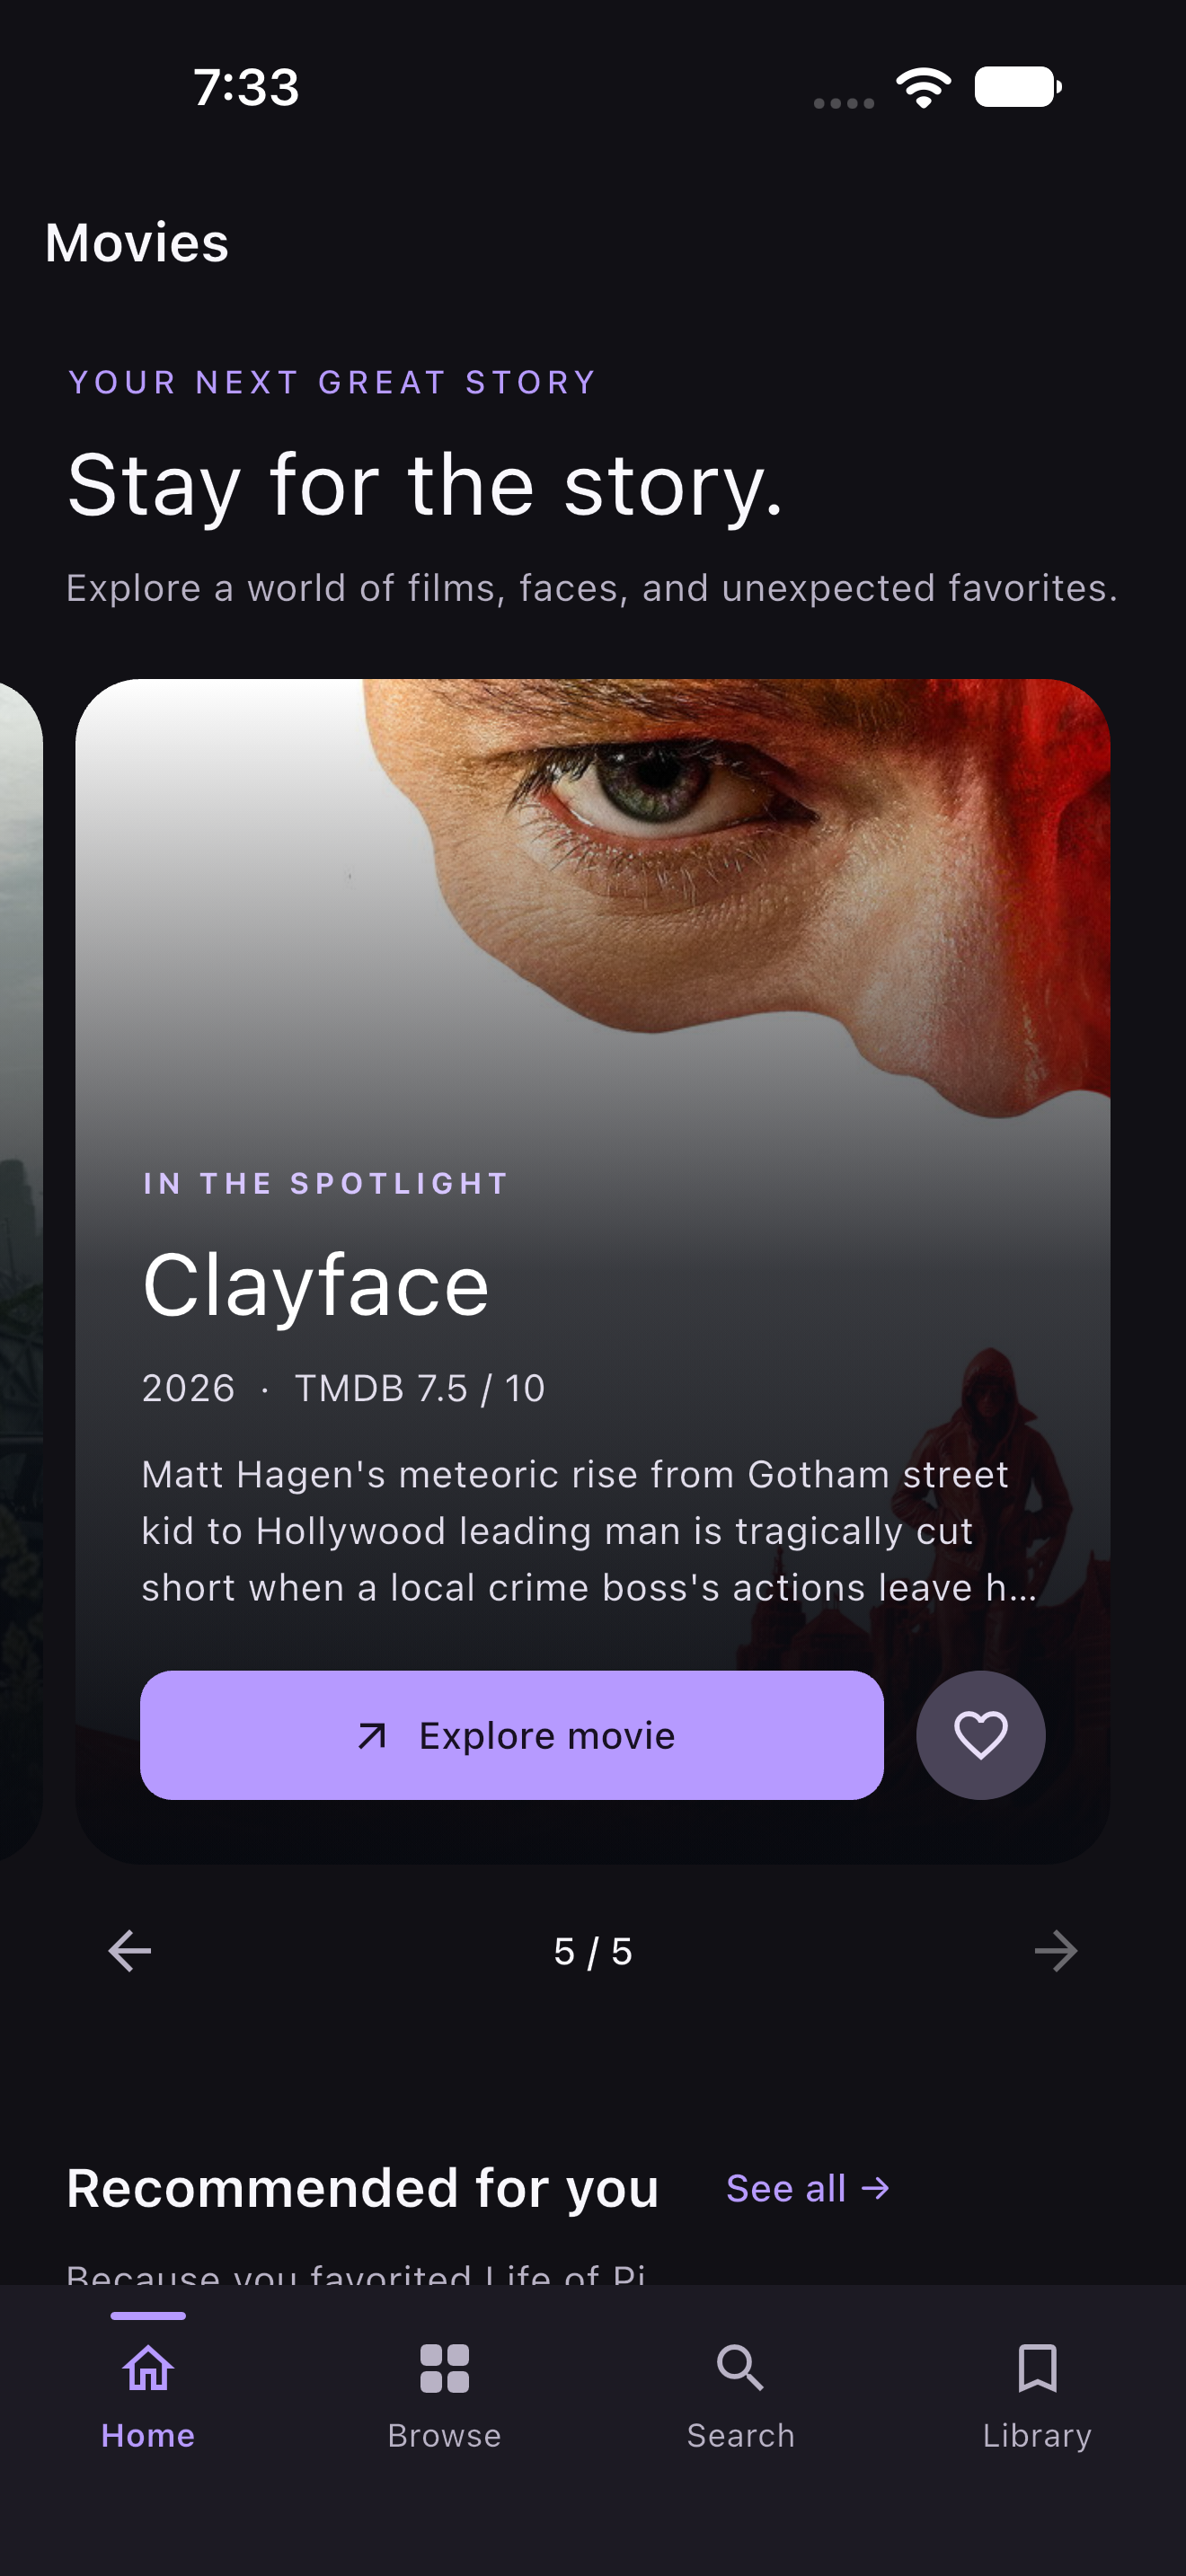

AFTER capture status: complete
Saved destination markers: [{'type': 'XCUIElementTypeOther', 'name': 'movies.search.screen', 'label': '', 'visible': 'true'}]


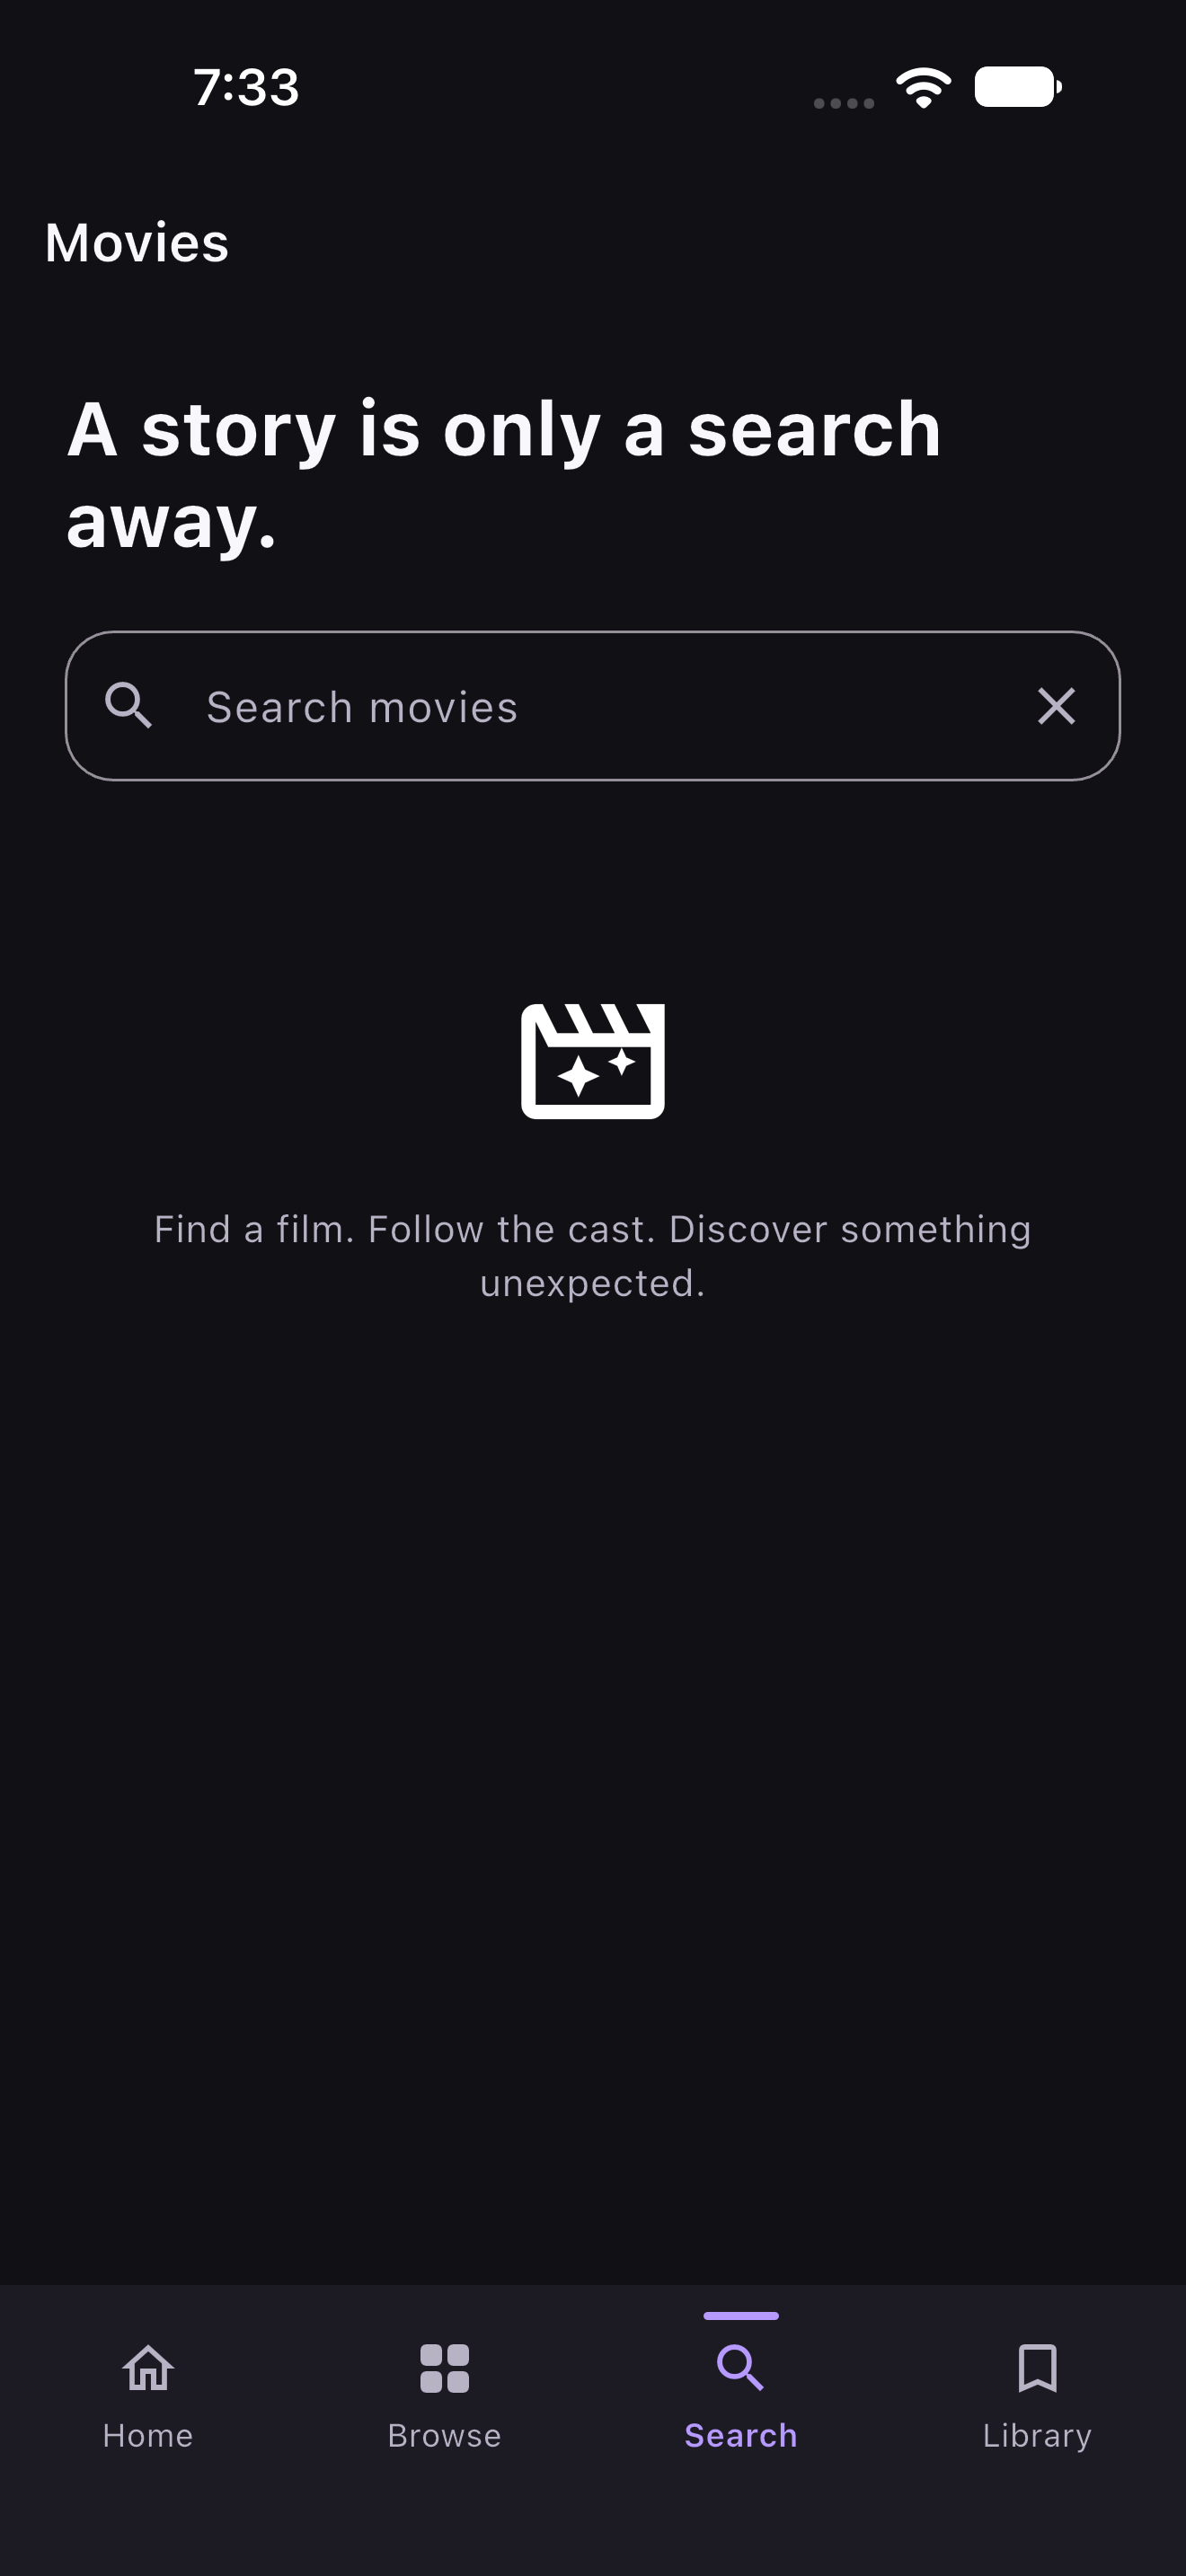

In [8]:
import json
from pathlib import Path
import xml.etree.ElementTree as ET
from IPython.display import Image, display

if not isinstance(globals().get("navigation_result"), dict):
    raise RuntimeError("Run the navigation exercise before previewing evidence.")
saved_navigation = json.loads(manifest_path.read_text(encoding="utf-8"))
print("Locator match count:", saved_navigation["action"].get("match_count"))
print("Tap attempted:", saved_navigation["action"]["attempted"])
print("Tap acknowledged:", saved_navigation["action"]["acknowledged"])
print("Search was already visible:", saved_navigation.get("already_on_search"))
print("Destination verification:", saved_navigation["verification_status"])
for phase in ("before", "after"):
    evidence = saved_navigation["evidence"].get(phase, {})
    print(phase.upper(), "capture status:", evidence.get("capture_status", "not_captured"))
    if "hierarchy" in evidence:
        try:
            root = ET.parse(evidence["hierarchy"]["path"]).getroot()
            markers = [{key: node.get(key, "") for key in ("type", "name", "label", "visible")}
                       for node in root.iter() if node.get("name") == saved_navigation["destination"]]
            print("Saved destination markers:", markers)
        except (ET.ParseError, OSError) as error:
            print("Hierarchy preview unavailable:", type(error).__name__)
    if "screenshot" in evidence:
        display(Image(filename=evidence["screenshot"]["path"], width=300))


### Read the single-action result, then pause

We have now connected **fresh observation → unique locator → guarded action → destination verification → new evidence**. This is one manually specified action, not an autonomous agent.

The native Search name was matched in the running app, rather than trusting an old XML count. Visibility/enabled checks reduce avoidable mistakes but do not guarantee a tap will succeed; the later destination check supplies separate evidence.

Only one `.click()` is issued. We do not type a query, clear an existing query, choose a movie, or evaluate Interstellar. Preserved Search state may already contain text from previous use; the exercise does not change it. If Search was already visible, describe the result as verifying that screen after one tap, not proving a transition from elsewhere.

The session and owned server are closed in the lifecycle cleanup. WDA or Movies can remain running, and the new active tab can remain Search. No automatic return tap is issued. Evidence, errors, and setup failures must remain separate from a full test verdict.

**Pause here:** the next small step will be to inspect and uniquely locate the Search input, enter the scenario's query, and observe the resulting state. We will introduce those behaviors separately from this one navigation action.


**Recorded live execution:** `2026-11-03T03:51:11.203569+00:00` (UTC). The accessibility-ID lookup returned **one** visible, enabled native Search button. Search was not visible before the action. The Appium log records **one click request**, followed by a successful visible Search-screen check and matching after-capture XML. Session deletion succeeded and Appium exited with code `0`.

The resulting Search screen includes the preserved query `life of pi`. The log records no typing or clearing requests. That text/results are existing app state, not a query issued by this exercise.

Saved manifest: `/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/search-tap-_hz13p9r/manifest.json`. Before/after XML and PNG files are alongside it and ignored by Git. Both actual screenshots are embedded above.

A separate offline diagnostic check reproduced a hierarchy-failure case that skipped screenshot capture. The capture helper now attempts XML and PNG independently; checks for source errors and malformed XML confirmed that an available PNG is retained, and preview parsing errors no longer hide it. These checks exercised diagnostic handling using temporary files; they are not reported as real application failures. The live navigation action was issued once.


[Index](README.md) · [Previous lesson](12_observe_ui.ipynb) · [Next lesson](14_search_query.ipynb)